In [3]:
"""
Veri Bilimi İçin İstatistik - Proje 2: Model Performans Değerlendirme
Veri Seti: Credit Card Fraud Detection
"""
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Görselleştirme ayarlarını yapalım
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Veri dosyası: Kaggle'dan indirilip data/ klasörüne konmalı
dosya_yolu = "../data/creditcard.csv"

def veri_yukle_ve_incele(yol):
    """
    Kredi kartı veri setini yükler, eksik veri kontrolü yapar ve 
    temel sınıf dağılımı istatistiklerini hesaplar.
    """
    df = pd.read_csv(yol)
    
    print(f"Veri Seti Boyutu: {df.shape[0]} satır, {df.shape[1]} sütun")
    print("Toplam Eksik Veri (NaN) Sayısı:", df.isnull().sum().max())
    
    sinif_dagilimi = df['Class'].value_counts()
    print("\nSınıf Dağılımı (0: Normal, 1: Fraud):")
    print(sinif_dagilimi)
    
    fraud_orani = (sinif_dagilimi[1] / len(df)) * 100
    print(f"Sahtekarlık (Fraud) Oranı: % {fraud_orani:.3f}")
    
    return df

# Fonksiyonu çalıştırıp veriyi 'df' değişkenine atayalım
df = veri_yukle_ve_incele(dosya_yolu)
display(df.head())

Veri Seti Boyutu: 284807 satır, 31 sütun
Toplam Eksik Veri (NaN) Sayısı: 0

Sınıf Dağılımı (0: Normal, 1: Fraud):
Class
0    284315
1       492
Name: count, dtype: int64
Sahtekarlık (Fraud) Oranı: % 0.173


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Model eğitiliyor, lütfen bekleyin...

--- TEST SETİ PERFORMANS METRİKLERİ ---
Accuracy (Doğruluk) : % 97.46
Precision (Kesinlik): % 5.88
Recall (Duyarlılık) : % 91.84

--- Confusion Matrix (Karmaşıklık Matrisi) ---
[[55424  1440]
 [    8    90]]


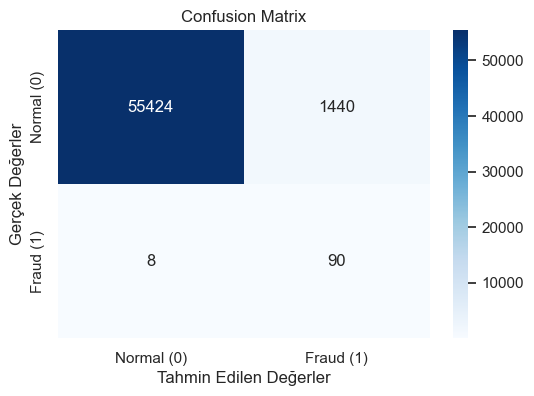

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, classification_report

def model_egit_ve_degerlendir(dataframe):
    """
    Veriyi Train/Test olarak böler, Lojistik Regresyon modeli eğitir ve 
    test seti üzerindeki performans metriklerini hesaplar.
    """
    # X (Özellikler) ve y (Hedef Değişken) ayrımı
    # 'Time' sütunu modelin kafasını karıştırabilir, onu çıkarıyoruz.
    X = dataframe.drop(['Class', 'Time'], axis=1) 
    y = dataframe['Class']
    
    # Veriyi %80 Eğitim, %20 Test olarak bölüyoruz (random_state ile tekrarlanabilirlik sağlıyoruz)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
    
    print("Model eğitiliyor, lütfen bekleyin...")
    # Dengesiz veri olduğu için class_weight='balanced' kullanıyoruz!
    model = LogisticRegression(max_iter=1000, class_weight='balanced')
    model.fit(X_train, y_train)
    
    # Test setinde tahmin yapma
    y_pred = model.predict(X_test)
    
    # Metrikleri Hesaplama
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    
    print("\n--- TEST SETİ PERFORMANS METRİKLERİ ---")
    print(f"Accuracy (Doğruluk) : % {acc*100:.2f}")
    print(f"Precision (Kesinlik): % {prec*100:.2f}")
    print(f"Recall (Duyarlılık) : % {rec*100:.2f}")
    
    print("\n--- Confusion Matrix (Karmaşıklık Matrisi) ---")
    cm = confusion_matrix(y_test, y_pred)
    print(cm)
    
    # Görselleştirme
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Normal (0)', 'Fraud (1)'], 
                yticklabels=['Normal (0)', 'Fraud (1)'])
    plt.ylabel('Gerçek Değerler')
    plt.xlabel('Tahmin Edilen Değerler')
    plt.title('Confusion Matrix')
    plt.show()
    
    return y_test, y_pred

# Fonksiyonu çalıştıralım
y_test, y_pred = model_egit_ve_degerlendir(df)

In [5]:
import math
import scipy.stats as stats

def istatistiksel_testler(y_test, y_pred):
    """
    Modelin doğruluk oranı üzerinden Binom dağılımı ile 
    %95 Güven Aralığı (Confidence Interval) hesaplar.
    """
    n = len(y_test) # Toplam test verisi sayısı
    k = (y_test == y_pred).sum() # Doğru bilinenlerin sayısı
    p_hat = k / n # Örneklem doğruluk oranı (Accuracy)
    
    print("--- İSTATİSTİKSEL MODELLEME ---")
    print(f"Toplam Deneme (n): {n}")
    print(f"Başarılı Tahmin (k): {k}")
    print(f"Örneklem Doğruluğu (p_hat): % {p_hat*100:.2f}")
    
    # %95 Güven Aralığı için Z-skoru (Kritik Değer = 1.96)
    z_score = stats.norm.ppf(0.975) 
    
    # Standart Hata (Standard Error) hesaplama
    # Formül: sqrt(p * (1-p) / n)
    standart_hata = math.sqrt((p_hat * (1 - p_hat)) / n)
    margin_of_error = z_score * standart_hata
    
    alt_sinir = p_hat - margin_of_error
    ust_sinir = p_hat + margin_of_error
    
    print("\n--- %95 GÜVEN ARALIĞI (CONFIDENCE INTERVAL) ---")
    print(f"Modelin gerçek doğruluğu %95 ihtimalle şu aralıktadır:")
    print(f"[% {alt_sinir*100:.2f}  -  % {ust_sinir*100:.2f}]")
    
    # Hipotez Testi (Z-Test)
    # H0: Model başarısı <= 0.50 (Rastgele tahmin)
    p_null = 0.50
    z_istatistigi = (p_hat - p_null) / math.sqrt((p_null * (1 - p_null)) / n)
    p_value = stats.norm.sf(z_istatistigi) # Tek yönlü (one-tailed) test
    
    print("\n--- HİPOTEZ TESTİ (H0: p <= 0.50) ---")
    print(f"Z-İstatistigi: {z_istatistigi:.2f}")
    print(f"P-değeri: {p_value:.10f}")
    
    if p_value < 0.05:
        print("Sonuç: p-değeri < 0.05 olduğu için H0 hipotezi REDDEDİLİR.")
        print("Yani modelin performansı istatistiksel olarak rastgele tahminden anlamlı derecede yüksektir.")
    else:
        print("Sonuç: H0 hipotezi reddedilemez.")

istatistiksel_testler(y_test, y_pred)

--- İSTATİSTİKSEL MODELLEME ---
Toplam Deneme (n): 56962
Başarılı Tahmin (k): 55514
Örneklem Doğruluğu (p_hat): % 97.46

--- %95 GÜVEN ARALIĞI (CONFIDENCE INTERVAL) ---
Modelin gerçek doğruluğu %95 ihtimalle şu aralıktadır:
[% 97.33  -  % 97.59]

--- HİPOTEZ TESTİ (H0: p <= 0.50) ---
Z-İstatistigi: 226.53
P-değeri: 0.0000000000
Sonuç: p-değeri < 0.05 olduğu için H0 hipotezi REDDEDİLİR.
Yani modelin performansı istatistiksel olarak rastgele tahminden anlamlı derecede yüksektir.


5-Fold Cross Validation başlatılıyor (Bu işlem 1-2 dakika sürebilir)...

--- 5-FOLD CROSS VALIDATION SONUÇLARI ---
Katman Skorları: [0.9763 0.9859 0.9646 0.9631 0.9779]
Ortalama Doğruluk (Mean Accuracy): % 97.36
Standart Sapma (Std Dev): % 0.858

Merkezi Limit Teoremi (MLT) simülasyonu hazırlanıyor...


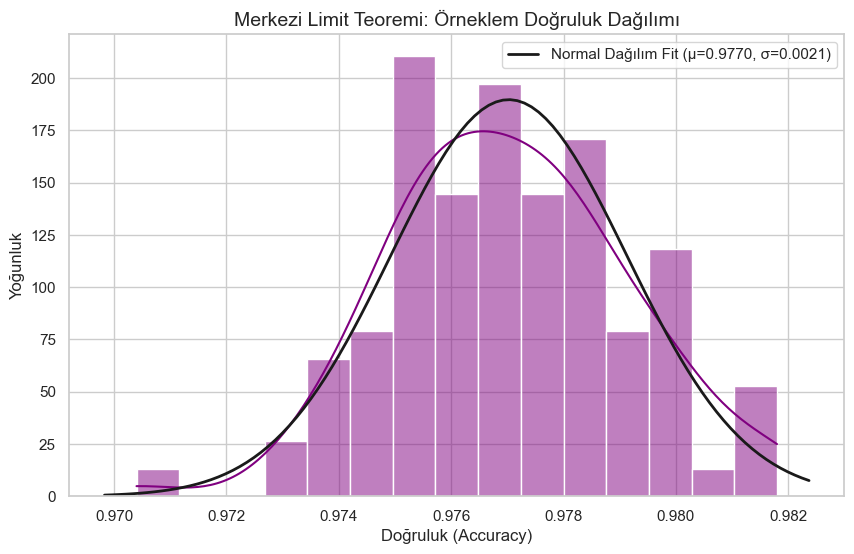

In [9]:
from sklearn.model_selection import cross_val_score
import scipy.stats as stats

def mlt_ve_cross_validation(X, y, model):
    """
    Model üzerinde 5-Fold CV uygular ve Merkezi Limit Teoremi'ni (MLT)
    kanıtlamak için doğruluk (accuracy) skorlarının dağılımını çizer.
    """
    print("5-Fold Cross Validation başlatılıyor (Bu işlem 1-2 dakika sürebilir)...")
    
    # 5-Fold CV Uygulaması
    cv_scores = cross_val_score(model, X, y, cv=5, scoring='accuracy', n_jobs=-1)
    
    print("\n--- 5-FOLD CROSS VALIDATION SONUÇLARI ---")
    print(f"Katman Skorları: {np.round(cv_scores, 4)}")
    print(f"Ortalama Doğruluk (Mean Accuracy): % {cv_scores.mean()*100:.2f}")
    print(f"Standart Sapma (Std Dev): % {cv_scores.std()*100:.3f}")
    
    # Merkezi Limit Teoremi Gösterimi İçin Bootstrapping
    # Sadece 5 veri noktasıyla çan eğrisi çizilemeyeceği için 
    # test setinden rastgele 100 farklı alt örneklem alıp ortalamalarının dağılımına bakıyoruz.
    print("\nMerkezi Limit Teoremi (MLT) simülasyonu hazırlanıyor...")
    
    orneklem_sayisi = 100
    orneklem_skorlari = []
    
    for i in range(orneklem_sayisi):
        # Veriden rastgele alt örneklemler çekme
        X_sample = X.sample(n=5000, random_state=i, replace=True)
        y_sample = y.loc[X_sample.index]
        
        score = model.score(X_sample, y_sample)
        orneklem_skorlari.append(score)
        
    # MLT Görselleştirme
    plt.figure(figsize=(10, 6))
    sns.histplot(orneklem_skorlari, kde=True, stat="density", bins=15, color="purple")
    
    # Teorik Normal Dağılım Eğrisi Ekleme
    mu, std = np.mean(orneklem_skorlari), np.std(orneklem_skorlari)
    xmin, xmax = plt.xlim()
    x = np.linspace(xmin, xmax, 100)
    p = stats.norm.pdf(x, mu, std)
    plt.plot(x, p, 'k', linewidth=2, label=f'Normal Dağılım Fit (μ={mu:.4f}, σ={std:.4f})')
    
    plt.title('Merkezi Limit Teoremi: Örneklem Doğruluk Dağılımı', fontsize=14)
    plt.xlabel('Doğruluk (Accuracy)', fontsize=12)
    plt.ylabel('Yoğunluk', fontsize=12)
    plt.legend()
    plt.show()

# Veri setini baştan veriyoruz, X ve y ayrımını yapalım
X = df.drop(['Class', 'Time'], axis=1)
y = df['Class']

# Daha önce kurduğumuz modeli parametre olarak gönderiyoruz
model_cv = LogisticRegression(max_iter=1000, class_weight='balanced')
model_cv.fit(X, y) # Tüm veriyle hızlıca fit edip gönderelim

mlt_ve_cross_validation(X, y, model_cv)

C:\Users\dikil\AppData\Local\Temp\ipykernel_33876\3922928294.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='Class', data=dataframe, palette='Set2')


Grafik başarıyla 'sinif_dagilimi_grafigi.png' adıyla kaydedildi!


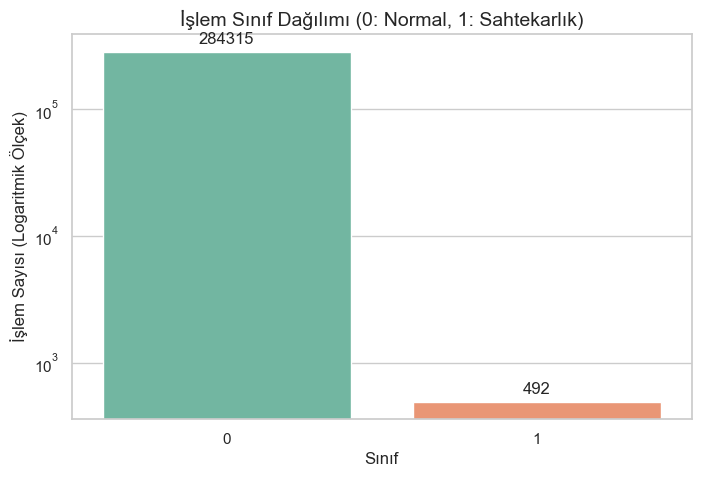

In [10]:
def dagilimi_gorsellestir_ve_kaydet(dataframe):
    plt.figure(figsize=(8, 5))
    ax = sns.countplot(x='Class', data=dataframe, palette='Set2')
    
    plt.title('İşlem Sınıf Dağılımı (0: Normal, 1: Sahtekarlık)', fontsize=14)
    plt.xlabel('Sınıf', fontsize=12)
    plt.ylabel('İşlem Sayısı (Logaritmik Ölçek)', fontsize=12)
    
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height())}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', 
                    xytext=(0, 9), textcoords='offset points')
    
    plt.yscale('log') 
    
    # Grafiği PNG olarak kaydet
    plt.savefig('sinif_dagilimi_grafigi.png', dpi=300, bbox_inches='tight')
    print("Grafik başarıyla 'sinif_dagilimi_grafigi.png' adıyla kaydedildi!")
    plt.show()

dagilimi_gorsellestir_ve_kaydet(df)